# 00 · MQTT en MonitorAire

[Guía de MQTT](README.md) · [Siguiente](01_modelo_pubsub_y_protocolo.ipynb)

## Qué vas a aprender

MQTT transporta las lecturas del monitor a través de un **broker** y permite observar el estado de cada dispositivo. La plataforma usa tres componentes de comunicación: **PubSubClient** en el ESP32, **Eclipse Mosquitto** como broker y **Eclipse Paho MQTT** en el proceso Python. Cada uno participa en una conexión diferente: la placa y Python son clientes de Mosquitto. El backend convierte, valida y guarda lecturas; el protocolo MQTT encamina bytes entre clientes según temas.

Para leer este recorrido basta abrir los notebooks como documentos Markdown. Los bloques con comandos indican en qué terminal ejecutarlos. El laboratorio usa su propio listener en loopback y admite datos sintéticos sin ESP32 ni PostgreSQL. Los notebooks complementarios incluyen ejercicios Python que puedes ejecutar con el kernel del entorno del proyecto.

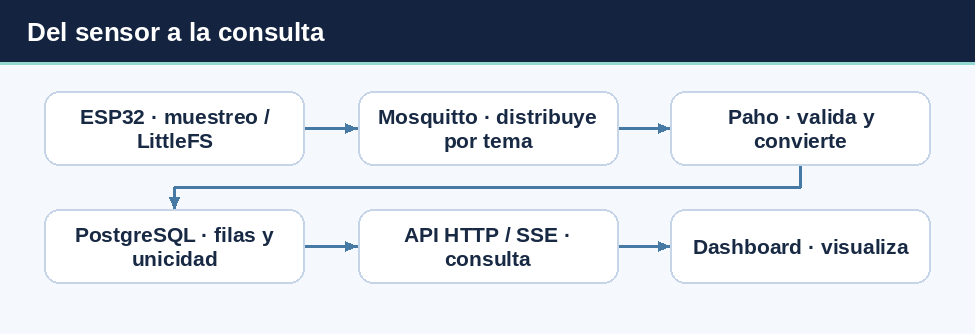

## Ruta de estudio

| Notebook | Pregunta que responde | Resultado |
| --- | --- | --- |
| [01 · Modelo pub/sub y protocolo](01_modelo_pubsub_y_protocolo.ipynb) | ¿Cómo entrega MQTT un mensaje y qué significa cada confirmación? | Distinguir TCP, MQTT, temas, QoS, sesiones, retain y Last Will. |
| [02 · Mosquitto y red local](02_broker_mosquitto_y_red.ipynb) | ¿A qué host y puerto se conecta cada cliente? | Arrancar el broker LAN o uno aislado y comprobar el enlace con las herramientas de Mosquitto. |
| [03 · Topics y contrato de datos](03_topics_y_contrato_de_datos.ipynb) | ¿Qué datos recibe y valida cada participante? | Leer los cuatro temas, interpretar las dos representaciones de telemetría y entender los timestamps. |
| [04 · Ingestión, reintentos y diagnóstico](04_ingesta_reintentos_y_diagnostico.ipynb) | ¿Cuándo se conserva o se confirma una lectura pendiente? | Seguir las rutas integrada e independiente, repetir una fila y localizar pérdidas o duplicados. |

## Cuatro conceptos para ubicar un problema

- **Conexión TCP.** El cliente alcanza la IP y el puerto del broker y abre un socket. Todavía falta que el broker acepte MQTT con CONNACK.
- **Recepción MQTT.** Un equipo recibe el mensaje por un tema compatible. En QoS 1, PUBACK confirma el intercambio MQTT entre dos extremos.
- **Procesamiento de aplicación.** El consumidor valida la lectura, decide qué guardar y puede publicar un resultado propio. En modo integrado, primero se confirma la transacción de PostgreSQL.
- **Avance en la placa.** La placa compara el identificador recibido en `/ack` con la fila pendiente y persiste la nueva posición del CSV en NVS. Ese ACK de aplicación viaja como un mensaje MQTT.

Un gráfico histórico incluye exclusivamente mediciones con hora válida. Antes de investigar el gráfico, comprueba que el mensaje llegó a `/tratado` y que la API registró la lectura. El contrato y la secuencia de recuperación se estudian en los capítulos 03 y 04.

## Lecturas complementarias del conversor Python

- [06 · Biblioteca estándar, tipos y conversión CSV → JSON](06_python_conversion_y_sintaxis.ipynb).
- [07 · Clase MQTT, hilos, callbacks y ACK](07_python_mqtt_clase_hilos_y_ack.ipynb).
- [09 · Módulos, responsabilidades y contratos](09_python_modular.ipynb).
- [10 · Ejercicios de los módulos sin broker](10_python_pruebas_modulares.ipynb).

Los capítulos 06, 07, 09 y 10 profundizan en el puente independiente. El capítulo 04 explica cuándo ese modo resulta útil y cómo difiere la confirmación del modo integrado.

[Guía de MQTT](README.md) · [Siguiente](01_modelo_pubsub_y_protocolo.ipynb)